# 2024 OPM FEVS – Benzer Cevap Veren Ajanslar

**Soru:** Hangi ajansların çalışanları ankete benzer cevaplar vermiş?

**Yöntem**
1. Her ajans için 76 Likert maddesinin **ağırlıklı % pozitif** değeri hesaplanır. Böylece her ajansın 76 boyutlu bir "cevap profili" olur.
2. Her madde ajanslar arasında standartlaştırılır (z-skoru).
3. İki tür benzerliğe bakılır:
   - **Seviye benzerliği:** Ajansların genel olumluluk düzeyi benzer mi? (Ward, z-skoru)
   - **Profil şekli benzerliği (ana analiz):** Her ajansın kendi ortalaması çıkarıldıktan sonra *hangi konularda görece güçlü, hangilerinde zayıf* olduğu benzer mi? Ölçüt Pearson korelasyonu. Bu yaklaşım "genel moral düzeyi" etkisini ayıklar ve ajansın karakterini gösterir.
4. Dendrogram, benzerlik matrisi, PCA haritası ve küme profilleri ile sonuçlar görselleştirilir.

> "All Other Agencies" (XX) birçok küçük ajansın karışımı olduğu için kümelemeye alınmaz.

In [1]:
from pathlib import Path
from textwrap import fill
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from IPython.display import display

pd.set_option("display.max_columns", 100); pd.set_option("display.width", 220)
pd.set_option("display.float_format", "{:,.1f}".format)

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":          # notebook'lar notebooks/ klasöründen çalışır
    ROOT = ROOT.parent
DATA, FIG, TAB = ROOT / "data", ROOT / "reports" / "figures", ROOT / "reports" / "tables"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)

def kaydet(ad):
    """Grafiği reports/figures klasörüne kaydeder ve gösterir."""
    plt.savefig(FIG / f"{ad}.png", dpi=110, bbox_inches="tight")
    plt.show()
df = pd.read_pickle(DATA / "fevs2024_clean.pkl")
cb = pd.read_excel(DATA / "2024" / "2024_OPM_FEVS_PRDF_Codebook.xlsx", sheet_name="Survey Items")
cb["VARIABLE"] = cb["VARIABLE"].str.strip()
text_map = cb.groupby("VARIABLE")["ITEM TEXT"].first().str.strip().to_dict()

Q16_COLS = [f"Q16_{i}" for i in range(1, 7)]
LIKERT_COLS = [c for c in df.columns if c.startswith("Q") and c not in Q16_COLS and c != "Q91"]

# --- stil ---
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
MARKERS = ["o", "s", "^", "D", "P", "X", "v", "*"]
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
DIV = LinearSegmentedColormap.from_list("div", ["#e34948", "#f3b3b2", "#f0efec", "#9ec5f4", "#1c5cab"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "font.family": ["Segoe UI", "DejaVu Sans"],
    "font.size": 10, "text.color": INK, "axes.labelcolor": INK2, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "xtick.color": MUTED, "ytick.color": INK2,
    "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True})

SHORT = {"AF": "Hava Kuvvetleri", "AG": "Tarım (USDA)", "AM": "USAID", "AR": "Kara Kuvvetleri (Army)",
         "BG": "PBGC", "BO": "OMB", "CM": "Ticaret (DOC)", "CT": "CFTC", "CU": "NCUA",
         "DD": "DoD Ajansları (OSD)", "DJ": "Adalet (DOJ)", "DL": "Çalışma (DOL)", "DN": "Enerji (DOE)",
         "DR": "FERC", "ED": "Eğitim (ED)", "EE": "EEOC", "EP": "EPA", "FT": "FTC", "GS": "GSA",
         "HE": "Sağlık (HHS)", "HS": "İç Güvenlik (DHS)", "HU": "Konut (HUD)", "IB": "USAGM",
         "IN": "İçişleri (DOI)", "NF": "NSF", "NL": "NLRB", "NQ": "NARA", "NU": "NRC",
         "NV": "Deniz Kuvvetleri (Navy)", "OM": "OPM", "SB": "SBA", "ST": "Dışişleri (State)",
         "SZ": "Sosyal Güvenlik (SSA)", "TD": "Ulaştırma (DOT)", "TR": "Hazine (Treasury)", "XX": "Diğer ajanslar"}
print(f"{len(df):,} satır, {df['agency'].nunique()} ajans")

674,207 satır, 36 ajans


## 1. Ajans profilleri – 76 madde × 36 ajans (% pozitif) ve ajans bilgileri

In [2]:
w = df["POSTWT"]
prof = {}
for q in LIKERT_COLS:
    m = df[q].notna()
    pos = (df.loc[m, q] >= 4) * w[m]
    prof[q] = 100 * pos.groupby(df.loc[m, "agency"], observed=True).sum() / w[m].groupby(df.loc[m, "agency"], observed=True).sum()
P = pd.DataFrame(prof)
P.index = P.index.astype(str)

def wshare(mask_col, cond):
    m = df[mask_col].notna()
    return (100 * (cond[m] * w[m]).groupby(df.loc[m, "agency"], observed=True).sum()
            / w[m].groupby(df.loc[m, "agency"], observed=True).sum()).reindex(P.index).astype(float)

info = pd.DataFrame({
    "ajans": [SHORT[a] for a in P.index],
    "katılımcı": df.groupby("agency", observed=True).size().reindex(P.index),
    "temsil_edilen_çalışan": df.groupby("agency", observed=True)["POSTWT"].sum().reindex(P.index).round(0),
}, index=P.index)
INDICES = {"EEI_Liderler": ["Q57", "Q58", "Q59", "Q61", "Q62"], "EEI_Yöneticiler": ["Q48", "Q50", "Q51", "Q52", "Q54"],
           "EEI_İçselİş": ["Q2", "Q3", "Q4", "Q6", "Q7"], "GSI": ["Q46", "Q70", "Q71", "Q72"],
           "PCI": ["Q20", "Q21", "Q22", "Q23"], "EXI": ["Q86", "Q87", "Q88", "Q89", "Q90"]}
info["EEI"] = P[INDICES["EEI_Liderler"]].mean(axis=1) / 3 + P[INDICES["EEI_Yöneticiler"]].mean(axis=1) / 3 \
              + P[INDICES["EEI_İçselİş"]].mean(axis=1) / 3
for k, qs in INDICES.items():
    info[k] = P[qs].mean(axis=1)
info["%_ayrılma_niyeti"] = wshare("DLEAVING", (df["DLEAVING"] != "No").astype(float))
info["%_sık_telecalışma"] = wshare("Q91", (df["Q91"].cat.codes == 0).astype(float))
info["%_sahada_zorunlu"] = wshare("Q91", (df["Q91"].cat.codes == 2).astype(float))
info["%_40_yaş_üstü"] = wshare("DAGEGRP", (df["DAGEGRP"] == "40 or Older").astype(float))
info["%_askerlik_geçmişi"] = wshare("DMIL", (df["DMIL"] == "Military Service").astype(float))
info["%_kadın"] = wshare("DSEX", (df["DSEX"] == "Female").astype(float))
display(info.sort_values("EEI", ascending=False))

,ajans,katılımcı,temsil_edilen_çalışan,EEI,EEI_Liderler,EEI_Yöneticiler,EEI_İçselİş,GSI,PCI,EXI,%_ayrılma_niyeti,%_sık_telecalışma,%_sahada_zorunlu,%_40_yaş_üstü,%_askerlik_geçmişi,%_kadın
agency,,,,,,,,,,,,,,,,
BG,PBGC,621,960.0,89.0,84.1,93.0,89.8,87.4,97.0,86.5,14.2,83.9,0.0,73.8,9.7,56.0
DR,FERC,1201,"1,520.0",85.7,82.3,91.8,83.0,79.9,92.7,80.8,24.3,75.3,0.2,63.7,8.1,45.5
GS,GSA,8268,"12,840.0",85.6,80.8,91.3,84.7,82.1,93.9,81.3,22.3,85.3,0.6,77.3,26.8,46.7
BO,OMB,500,687.0,81.9,75.1,87.1,83.4,77.6,91.9,86.7,41.3,63.1,0.4,53.0,5.1,59.1
EP,EPA,9366,"15,192.0",80.7,72.7,88.0,81.5,77.3,91.2,83.7,24.6,75.5,0.6,68.2,11.2,54.9
FT,FTC,879,"1,206.0",80.3,65.7,91.0,84.0,68.5,95.7,86.0,24.5,84.4,0.2,59.0,6.3,46.5
CU,NCUA,874,"1,165.0",80.0,73.7,86.1,80.4,76.4,91.1,79.0,20.6,65.8,5.1,74.4,18.2,39.5
OM,OPM,1489,"2,797.0",80.0,73.5,87.3,79.2,74.9,90.6,79.2,28.1,79.0,2.6,74.7,18.6,68.9
DN,Enerji (DOE),11037,"14,342.0",79.8,70.6,87.6,81.3,74.8,91.8,79.4,28.1,58.2,8.2,76.2,28.0,36.3


## 2. Standartlaştırma ve küme sayısının seçimi

,2,3,4,5,6,7,8
"seviye (Ward, öklid)",0.4,0.3,0.3,0.3,0.2,0.2,0.2
"profil şekli (Ward, korelasyon)",0.2,0.2,0.2,0.2,0.2,0.2,0.2


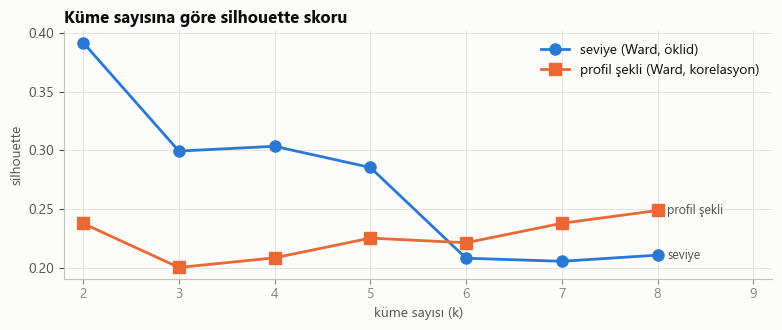

In [3]:
Pc = P.drop(index="XX")
Z = (Pc - Pc.mean()) / Pc.std()                                  # seviye: madde bazında z-skoru
R = Z.sub(Z.mean(axis=1), axis=0).div(Z.std(axis=1), axis=0)     # şekil: her ajansın kendi ortalaması çıkarılmış
L_lvl = linkage(Z.values, method="ward")
L = linkage(R.values, method="ward")

sil = pd.DataFrame({
    "seviye (Ward, öklid)": {k: silhouette_score(Z.values, fcluster(L_lvl, k, "maxclust")) for k in range(2, 9)},
    "profil şekli (Ward, korelasyon)": {k: silhouette_score(R.values, fcluster(L, k, "maxclust"), metric="correlation")
                                       for k in range(2, 9)}})
display(sil.T.round(3))

fig, ax = plt.subplots(figsize=(8, 3.4))
for i, c in enumerate(sil.columns):
    ax.plot(sil.index, sil[c], color=SERIES[i], lw=2, marker=MARKERS[i], ms=8, label=c)
    ax.text(8.1, sil[c].iloc[-1], c.split(" (")[0], color=INK2, va="center", fontsize=9)
ax.set_xlim(1.8, 9.2); ax.set_xlabel("küme sayısı (k)"); ax.set_ylabel("silhouette")
ax.legend(frameon=False, loc="upper right")
ax.set_title("Küme sayısına göre silhouette skoru")
plt.tight_layout(); kaydet("03_01_silhouette")

**Yorum:** Silhouette değerleri 0,2–0,4 aralığında. Bu, ajansların keskin biçimde ayrışmadığını, **sürekli bir yelpaze** üzerinde durduğunu gösterir. Kümeler kesin sınırlar olarak değil, "birbirine en çok benzeyen ajans grupları" olarak okunmalıdır.

- **Seviye kümeleri** için k = 4 (yüksek → düşük moral kademeleri).
- **Profil şekli** için k = 6 seçildi: k = 5'te iki anlamlı grup birleşiyor, k = 7'de yalnızca iki ajanslık bir küme ayrılıyor.

In [4]:
K_LVL, K = 4, 6

def renumber(lab, key):
    lab = pd.Series(lab, index=Z.index)
    order = key.groupby(lab).mean().sort_values(ascending=False).index
    return lab.map({o: n for n, o in enumerate(order, 1)})

cl_lvl = renumber(fcluster(L_lvl, K_LVL, "maxclust"), info.loc[Z.index, "EEI"])
cl = renumber(fcluster(L, K, "maxclust"), info.loc[Z.index, "EEI"])

# Küme adları: internet araştırması + küme profillerine göre (bkz. bölüm 7)
NAMES = {"AR": "Savunma ve güvenlik", "ST": "Dış ilişkiler ve politika", "IN": "Bilim, doğal kaynak ve teknik",
         "FT": "Düzenleyici / denetleyici kurullar", "TR": "Finans, sosyal yardım ve idari hizmet",
         "SB": "Hizmet ve hak koruma (karma)"}
KUME_ADI = {cl[a]: f"K{cl[a]} · {n}" for a, n in NAMES.items()}
assert len(KUME_ADI) == K, "Küme adları çakışıyor – NAMES sözlüğünü kontrol edin"

seviye = pd.DataFrame({"ajanslar": info.loc[Z.index].groupby(cl_lvl)["ajans"].apply(", ".join),
                       "ortalama_EEI": info.loc[Z.index].groupby(cl_lvl)["EEI"].mean()})
seviye.index = [f"Kademe {k}" for k in seviye.index]
print("Seviye kümeleri (genel olumluluk kademeleri):")
display(seviye)

print("Profil şekli kümeleri:")
pd.DataFrame({"ajanslar": info.loc[Z.index].groupby(cl)["ajans"].apply(", ".join)}).rename(index=KUME_ADI)

Seviye kümeleri (genel olumluluk kademeleri):


,ajanslar,ortalama_EEI
Kademe 1,"PBGC, FERC, GSA",86.7
Kademe 2,"OMB, NCUA, Enerji (DOE), EEOC, EPA, FTC, Sağlı...",79.9
Kademe 3,"Hava Kuvvetleri, Tarım (USDA), Kara Kuvvetleri...",74.4
Kademe 4,"USAID, DoD Ajansları (OSD), Adalet (DOJ), İç G...",69.7


Profil şekli kümeleri:


,ajanslar
"K1 · Finans, sosyal yardım ve idari hizmet","PBGC, Ticaret (DOC), NCUA, Çalışma (DOL), FERC..."
K2 · Hizmet ve hak koruma (karma),"EEOC, Sağlık (HHS), Konut (HUD), USAGM, OPM, SBA"
K3 · Dış ilişkiler ve politika,"USAID, OMB, EPA, Dışişleri (State)"
K4 · Düzenleyici / denetleyici kurullar,"CFTC, Eğitim (ED), FTC, NLRB"
"K5 · Bilim, doğal kaynak ve teknik","Tarım (USDA), Enerji (DOE), İçişleri (DOI), NS..."
K6 · Savunma ve güvenlik,"Hava Kuvvetleri, Kara Kuvvetleri (Army), DoD A..."


## 3. Dendrogram – profil şekline göre hiyerarşik benzerlik

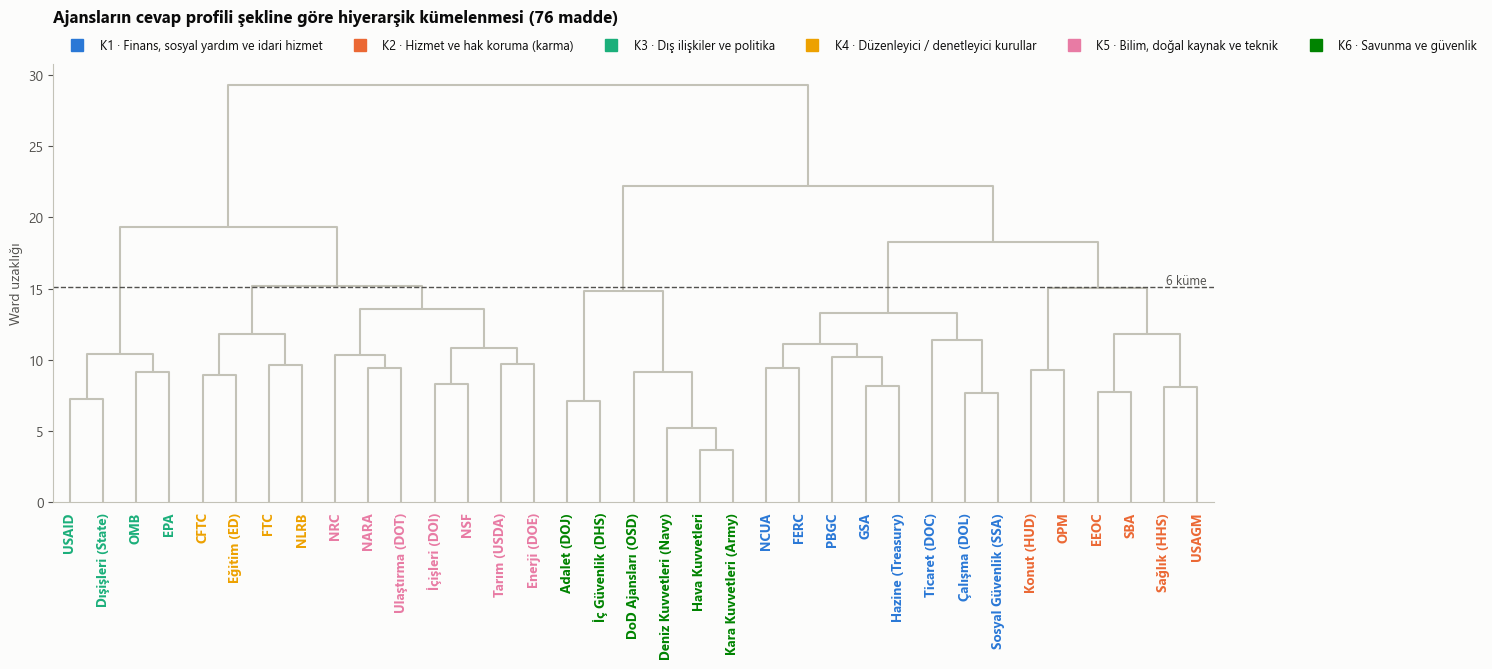

In [5]:
fig, ax = plt.subplots(figsize=(15, 6.8))
labels = [SHORT[a] for a in R.index]
lab2cl = {SHORT[a]: c for a, c in cl.items()}
dn = dendrogram(L, labels=labels, leaf_rotation=90, color_threshold=0, above_threshold_color=AXIS, ax=ax)
for t in ax.get_xticklabels():
    t.set_color(SERIES[lab2cl[t.get_text()] - 1]); t.set_fontsize(9.5); t.set_fontweight("bold")
thr = (L[-K, 2] + L[-(K - 1), 2]) / 2
ax.axhline(thr, color=INK2, ls="--", lw=1)
ax.text(ax.get_xlim()[1], thr, f"{K} küme  ", va="bottom", ha="right", color=INK2, fontsize=9)
ax.grid(False); ax.set_ylabel("Ward uzaklığı")
handles = [plt.Line2D([], [], color=SERIES[k - 1], marker="s", ls="", ms=9, label=KUME_ADI[k]) for k in range(1, K + 1)]
ax.legend(handles=handles, frameon=False, ncol=6, loc="lower left", bbox_to_anchor=(0, 1.0), fontsize=9)
ax.set_title("Ajansların cevap profili şekline göre hiyerarşik kümelenmesi (76 madde)", pad=30)
plt.tight_layout(); kaydet("03_02_dendrogram")

## 4. Benzerlik matrisi ve her ajansın en çok benzediği ajanslar

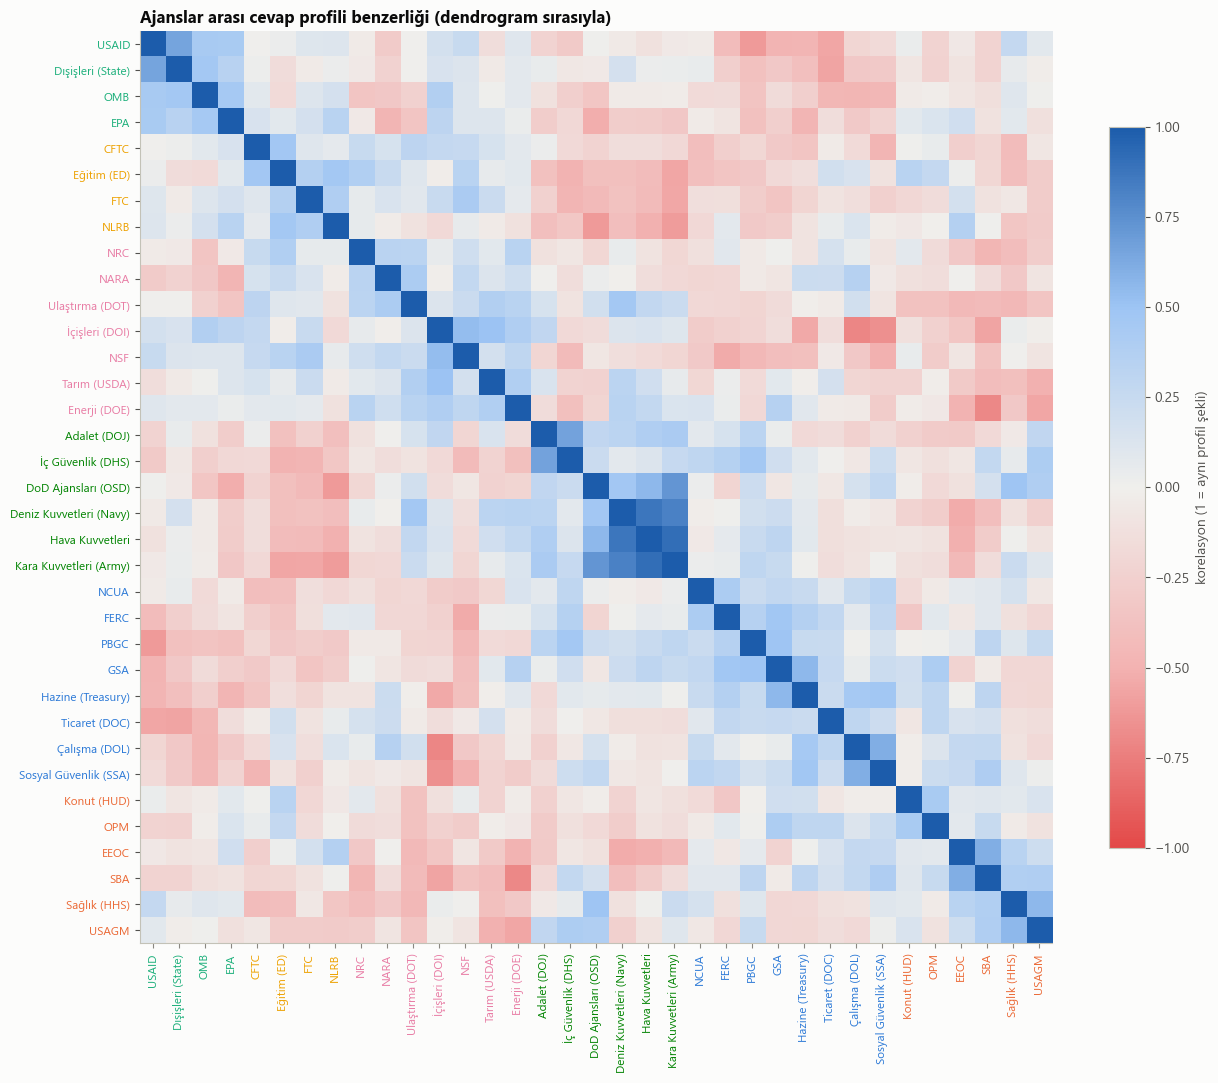

,küme,1. en benzer,2.,3.
USAID,K3 · Dış ilişkiler ve politika,Dışişleri (State) (0.65),OMB (0.43),EPA (0.42)
Dışişleri (State),K3 · Dış ilişkiler ve politika,USAID (0.65),OMB (0.46),EPA (0.34)
OMB,K3 · Dış ilişkiler ve politika,Dışişleri (State) (0.46),EPA (0.45),USAID (0.43)
EPA,K3 · Dış ilişkiler ve politika,OMB (0.45),USAID (0.42),Dışişleri (State) (0.34)
CFTC,K4 · Düzenleyici / denetleyici kurullar,Eğitim (ED) (0.47),Ulaştırma (DOT) (0.31),İçişleri (DOI) (0.26)
Eğitim (ED),K4 · Düzenleyici / denetleyici kurullar,CFTC (0.47),NLRB (0.46),NRC (0.38)
FTC,K4 · Düzenleyici / denetleyici kurullar,NSF (0.41),NLRB (0.39),Eğitim (ED) (0.37)
NLRB,K4 · Düzenleyici / denetleyici kurullar,Eğitim (ED) (0.46),FTC (0.39),EEOC (0.37)
NRC,"K5 · Bilim, doğal kaynak ve teknik",Eğitim (ED) (0.38),Enerji (DOE) (0.33),NARA (0.32)
NARA,"K5 · Bilim, doğal kaynak ve teknik",Ulaştırma (DOT) (0.41),Çalışma (DOL) (0.35),NRC (0.32)


In [6]:
S = R.T.corr().rename(index=SHORT, columns=SHORT)
leaf_order = [SHORT[R.index[i]] for i in dn["leaves"]]
S = S.loc[leaf_order, leaf_order]
fig, ax = plt.subplots(figsize=(13, 11.5))
im = ax.imshow(S.values, cmap=DIV, vmin=-1, vmax=1)
ax.set_xticks(range(len(S)), S.columns, rotation=90, fontsize=8.5)
ax.set_yticks(range(len(S)), S.index, fontsize=8.5); ax.grid(False)
for t in ax.get_xticklabels() + ax.get_yticklabels():
    t.set_color(SERIES[lab2cl[t.get_text()] - 1])
fig.colorbar(im, ax=ax, shrink=0.7, label="korelasyon (1 = aynı profil şekli)")
ax.set_title("Ajanslar arası cevap profili benzerliği (dendrogram sırasıyla)")
plt.tight_layout(); kaydet("03_03_benzerlik_matrisi")

nn = pd.DataFrame({a: [f"{i} ({v:.2f})" for i, v in S.loc[a].drop(a).nlargest(3).items()] for a in S.index},
                  index=["1. en benzer", "2.", "3."]).T
nn.insert(0, "küme", [KUME_ADI[lab2cl[a]] for a in nn.index])
nn

## 5. PCA haritası – ajansların 2 boyutlu konumu (profil şekli)

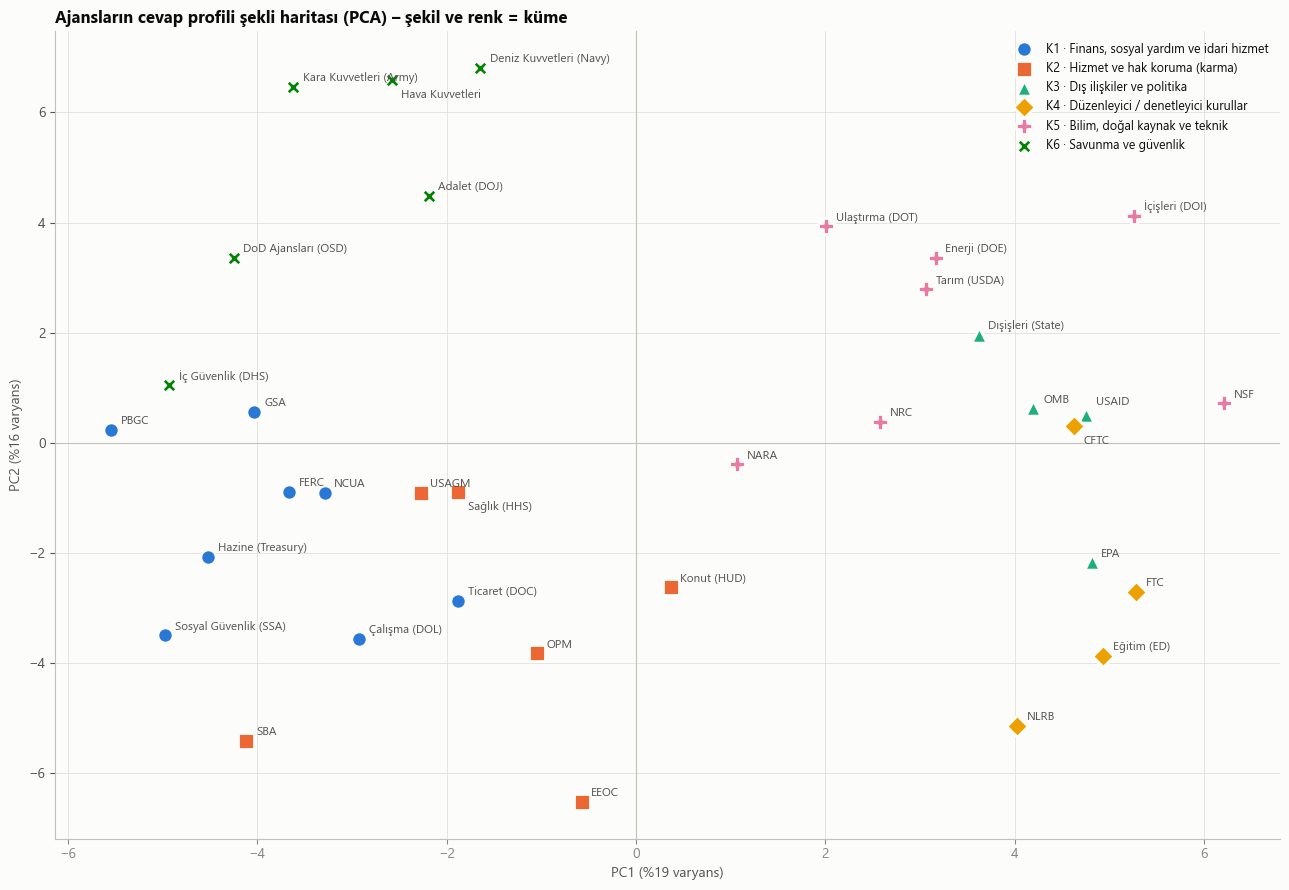


PC1 – negatif uçta (üst 5) ve pozitif uçta (alt 5) olan maddeler:


,yük,madde
Q43,-0.2,My organization has prepared me for potential ...
Q41,-0.2,The approval process in my organization allows...
Q62,-0.2,I have a high level of respect for my organiza...
Q5,-0.2,My workload is reasonable.
Q4,-0.2,I know what is expected of me on the job.
Q89,0.2,I identify with the mission of my organization.
Q49,0.2,My supervisor supports my need to balance work...
Q24,0.2,"New hires in my work unit (i.e., hired in the ..."
Q90,0.2,It is important to me that my work contribute ...
Q25,0.2,I can influence decisions in my work unit.



PC2 – negatif uçta (üst 5) ve pozitif uçta (alt 5) olan maddeler:


,yük,madde
Q39,-0.2,"My organization shares results (for example, t..."
Q59,-0.2,Managers communicate the goals of the organiza...
Q89,-0.2,I identify with the mission of my organization.
Q61,-0.1,"Overall, how good a job do you feel is being d..."
Q44,-0.1,My organization has prepared me for potential ...
Q5,0.2,My workload is reasonable.
Q43,0.2,My organization has prepared me for potential ...
Q13,0.3,I have the autonomy to decide how I do my job.
Q25,0.3,I can influence decisions in my work unit.
Q14,0.4,I can make decisions about my work without get...


In [7]:
pca = PCA(n_components=2).fit(R.values)
xy = pca.transform(R.values)
ev = pca.explained_variance_ratio_ * 100
load = pd.DataFrame(pca.components_.T, index=R.columns, columns=["PC1", "PC2"])

fig, ax = plt.subplots(figsize=(13, 9))
for k in range(1, K + 1):
    m = (cl == k).values
    ax.scatter(xy[m, 0], xy[m, 1], s=120, color=SERIES[k - 1], marker=MARKERS[k - 1],
               edgecolor=SURFACE, linewidth=2, label=KUME_ADI[k], zorder=3)
OFFSET = {"AF": (7, -13), "CT": (7, -13), "HE": (7, -13), "AM": (7, 7)}   # çakışan etiketler
for (x, y), a in zip(xy, R.index):
    ax.annotate(SHORT[a], (x, y), xytext=OFFSET.get(a, (7, 4)), textcoords="offset points", fontsize=8.5, color=INK2)
ax.axhline(0, color=AXIS, lw=0.8); ax.axvline(0, color=AXIS, lw=0.8)
ax.set_xlabel(f"PC1 (%{ev[0]:.0f} varyans)"); ax.set_ylabel(f"PC2 (%{ev[1]:.0f} varyans)")
ax.legend(frameon=False, loc="best", fontsize=9)
ax.set_title("Ajansların cevap profili şekli haritası (PCA) – şekil ve renk = küme")
plt.tight_layout(); kaydet("03_04_PCA_haritasi")

for pc in ["PC1", "PC2"]:
    s = load[pc].sort_values()
    idx = pd.concat([s.head(5), s.tail(5)]).index
    print(f"\n{pc} – negatif uçta (üst 5) ve pozitif uçta (alt 5) olan maddeler:")
    display(pd.DataFrame({"yük": load.loc[idx, pc], "madde": [text_map[q][:95] for q in idx]}).round(3))

## 6. Küme profilleri

In [8]:
info_c = info.drop(index="XX").join(cl.rename("küme"))
num_cols = ["EEI", "GSI", "PCI", "EXI", "EEI_Liderler", "EEI_Yöneticiler", "%_ayrılma_niyeti",
            "%_sık_telecalışma", "%_sahada_zorunlu", "%_40_yaş_üstü", "%_askerlik_geçmişi", "%_kadın"]
ozet = info_c.groupby("küme")[num_cols].mean()
ozet.insert(0, "temsil_edilen_çalışan", info_c.groupby("küme")["temsil_edilen_çalışan"].sum())
ozet.insert(0, "ajans_sayısı", info_c.groupby("küme").size())
ozet.loc["Tüm ajanslar (ort.)"] = [len(info_c), info_c["temsil_edilen_çalışan"].sum()] + list(info_c[num_cols].mean())
ozet = ozet.rename(index=KUME_ADI)
ozet.round(1)

,ajans_sayısı,temsil_edilen_çalışan,EEI,GSI,PCI,EXI,EEI_Liderler,EEI_Yöneticiler,%_ayrılma_niyeti,%_sık_telecalışma,%_sahada_zorunlu,%_40_yaş_üstü,%_askerlik_geçmişi,%_kadın
küme,,,,,,,,,,,,,,
"K1 · Finans, sosyal yardım ve idari hizmet",8.0,"235,581.0",79.5,72.8,89.6,77.7,72.7,86.6,26.0,69.2,3.2,74.0,16.0,51.3
K2 · Hizmet ve hak koruma (karma),6.0,"106,012.0",77.1,71.6,88.7,80.5,69.5,83.5,28.9,68.5,5.0,78.9,16.4,61.6
K3 · Dış ilişkiler ve politika,4.0,"47,582.0",75.7,70.0,88.2,80.6,66.5,83.3,31.9,46.6,9.3,68.2,11.4,56.4
K4 · Düzenleyici / denetleyici kurullar,4.0,"7,013.0",75.1,66.5,90.5,78.5,61.9,86.5,27.2,84.2,0.4,75.0,9.1,55.2
"K5 · Bilim, doğal kaynak ve teknik",7.0,"228,723.0",74.4,67.5,88.2,76.6,61.3,84.5,31.5,45.8,10.2,74.6,21.5,44.1
K6 · Savunma ve güvenlik,6.0,"1,050,741.0",71.6,63.9,82.6,73.3,61.0,79.8,40.9,22.1,37.5,71.8,40.1,35.8
Tüm ajanslar (ort.),35.0,"1,675,652.0",75.8,69.0,87.9,77.6,65.9,84.1,31.0,55.5,11.2,74.0,20.0,50.0


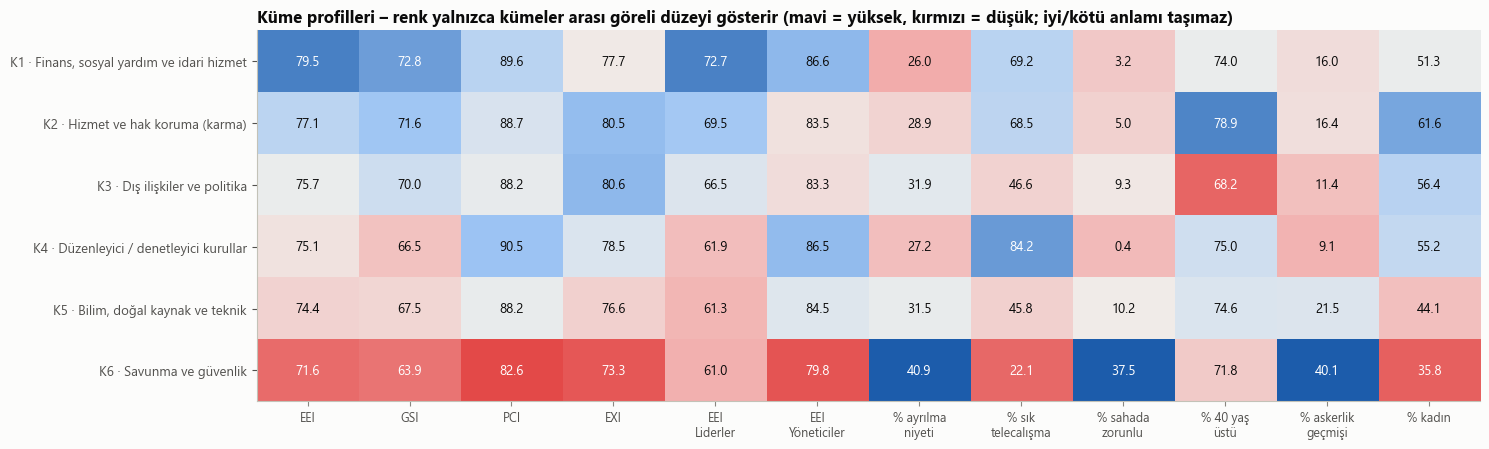

In [9]:
H = ozet.drop(index="Tüm ajanslar (ort.)")[num_cols].astype(float)
Hz = (H - H.mean()) / H.std()
fig, ax = plt.subplots(figsize=(15, 4.6))
ax.imshow(Hz.values, cmap=DIV, vmin=-1.8, vmax=1.8, aspect="auto"); ax.grid(False)
ax.set_xticks(range(len(num_cols)), [fill(c.replace("_", " "), 11) for c in num_cols], fontsize=9, color=INK2)
ax.set_yticks(range(len(H)), H.index, fontsize=9.5)
for i in range(H.shape[0]):
    for j in range(H.shape[1]):
        ax.text(j, i, f"{H.iat[i, j]:.1f}", ha="center", va="center", fontsize=9.5,
                color="white" if abs(Hz.iat[i, j]) > 1.2 else INK)
ax.set_title("Küme profilleri – renk yalnızca kümeler arası göreli düzeyi gösterir (mavi = yüksek, kırmızı = düşük; iyi/kötü anlamı taşımaz)")
plt.tight_layout(); kaydet("03_05_kume_profilleri")

In [10]:
# Her kümeyi tanımlayan maddeler: kendi profiline göre görece güçlü / zayıf olduğu konular
Rc = R.groupby(cl).mean().T
tanim = {}
for k in range(1, K + 1):
    s = Rc[k].sort_values()
    idx = pd.concat([s.tail(5)[::-1], s.head(5)]).index
    t = pd.DataFrame({"yön": ["▲ görece güçlü"] * 5 + ["▼ görece zayıf"] * 5,
                      "şekil_skoru": s[idx].values,
                      "%_pozitif_küme": Pc.loc[cl[cl == k].index, idx].mean().values,
                      "%_pozitif_tüm_ajanslar": Pc[idx].mean().values,
                      "madde": [f"{q}: {text_map[q][:85]}" for q in idx]}, index=idx)
    tanim[k] = t
    print(f"\n■ {KUME_ADI[k]}:  {', '.join(info_c.loc[cl[cl == k].index, 'ajans'])}")
    display(t.round(2))


■ K1 · Finans, sosyal yardım ve idari hizmet:  PBGC, Ticaret (DOC), NCUA, Çalışma (DOL), FERC, GSA, Sosyal Güvenlik (SSA), Hazine (Treasury)


,yön,şekil_skoru,%_pozitif_küme,%_pozitif_tüm_ajanslar,madde
Q59,▲ görece güçlü,1.0,79.1,71.8,Q59: Managers communicate the goals of the org...
Q47,▲ görece güçlü,0.9,65.5,55.2,Q47: I believe the results of this survey will...
Q38,▲ görece güçlü,0.9,84.5,80.4,Q38: I have a good understanding of my organiz...
Q4,▲ görece güçlü,0.8,86.6,83.2,Q4: I know what is expected of me on the job.
Q56,▲ görece güçlü,0.8,85.8,79.9,Q56: My supervisor provides me with performanc...
Q90,▼ görece zayıf,-1.9,92.9,93.5,Q90: It is important to me that my work contri...
Q89,▼ görece zayıf,-1.5,81.9,82.7,Q89: I identify with the mission of my organiz...
Q25,▼ görece zayıf,-1.5,71.6,72.7,Q25: I can influence decisions in my work unit.
Q86,▼ görece zayıf,-1.2,67.2,67.4,Q86: My job inspires me.
Q24,▼ görece zayıf,-1.0,68.7,68.0,"Q24: New hires in my work unit (i.e., hired in..."



■ K2 · Hizmet ve hak koruma (karma):  EEOC, Sağlık (HHS), Konut (HUD), USAGM, OPM, SBA


,yön,şekil_skoru,%_pozitif_küme,%_pozitif_tüm_ajanslar,madde
Q86,▲ görece güçlü,1.1,71.8,67.4,Q86: My job inspires me.
Q33,▲ görece güçlü,1.0,76.2,71.8,Q33: Employees in my work unit consistently lo...
Q62,▲ görece güçlü,0.9,71.0,65.9,Q62: I have a high level of respect for my org...
Q89,▲ görece güçlü,0.8,85.6,82.7,Q89: I identify with the mission of my organiz...
Q57,▲ görece güçlü,0.8,59.4,54.6,"Q57: In my organization, senior leaders genera..."
Q25,▼ görece zayıf,-1.7,68.8,72.7,Q25: I can influence decisions in my work unit.
Q14,▼ görece zayıf,-1.4,62.0,64.9,Q14: I can make decisions about my work withou...
Q8,▼ görece zayıf,-1.3,72.1,74.5,Q8: I can disclose a suspected violation of an...
Q36,▼ görece zayıf,-1.2,77.6,80.9,Q36: Employees are protected from health and s...
Q51,▼ görece zayıf,-1.1,88.0,88.8,Q51: My supervisor treats me with respect.



■ K3 · Dış ilişkiler ve politika:  USAID, OMB, EPA, Dışişleri (State)


...

,yön,şekil_skoru,%_pozitif_küme,%_pozitif_tüm_ajanslar,madde
Q34,▲ görece güçlü,1.2,84.8,79.2,Q34: Employees in my work unit support my need...
Q23,▲ görece güçlü,1.2,88.6,84.5,Q23: Employees in my work unit adapt to changi...
Q22,▲ görece güçlü,1.1,91.8,87.6,Q22: Employees in my work unit produce high-qu...
Q44,▲ görece güçlü,1.1,90.0,86.4,Q44: My organization has prepared me for poten...
Q24,▲ görece güçlü,1.1,74.7,68.0,"Q24: New hires in my work unit (i.e., hired in..."
Q43,▼ görece zayıf,-2.1,65.9,75.9,Q43: My organization has prepared me for poten...
Q62,▼ görece zayıf,-1.3,58.0,65.9,Q62: I have a high level of respect for my org...
Q14,▼ görece zayıf,-1.1,59.8,64.9,Q14: I can make decisions about my work withou...
Q38,▼ görece zayıf,-1.0,77.0,80.4,Q38: I have a good understanding of my organiz...
Q57,▼ görece zayıf,-1.0,47.5,54.6,"Q57: In my organization, senior leaders genera..."



■ K5 · Bilim, doğal kaynak ve teknik:  Tarım (USDA), Enerji (DOE), İçişleri (DOI), NSF, NARA, NRC, Ulaştırma (DOT)


,yön,şekil_skoru,%_pozitif_küme,%_pozitif_tüm_ajanslar,madde
Q14,▲ görece güçlü,1.5,67.6,64.9,Q14: I can make decisions about my work withou...
Q36,▲ görece güçlü,1.3,84.0,80.9,Q36: Employees are protected from health and s...
Q13,▲ görece güçlü,1.1,75.5,73.7,Q13: I have the autonomy to decide how I do my...
Q25,▲ görece güçlü,1.1,75.0,72.7,Q25: I can influence decisions in my work unit.
Q49,▲ görece güçlü,1.0,89.5,88.1,Q49: My supervisor supports my need to balance...
Q62,▼ görece zayıf,-1.4,59.8,65.9,Q62: I have a high level of respect for my org...
Q58,▼ görece zayıf,-1.2,60.3,65.7,Q58: My organization's senior leaders maintain...
Q57,▼ görece zayıf,-1.1,49.3,54.6,"Q57: In my organization, senior leaders genera..."
Q42,▼ görece zayıf,-1.0,66.2,70.2,Q42: My organization effectively adapts to cha...
Q65,▼ görece zayıf,-1.0,53.3,58.3,Q65: Management makes effective changes to add...



■ K6 · Savunma ve güvenlik:  Hava Kuvvetleri, Kara Kuvvetleri (Army), DoD Ajansları (OSD), Adalet (DOJ), İç Güvenlik (DHS), Deniz Kuvvetleri (Navy)


,yön,şekil_skoru,%_pozitif_küme,%_pozitif_tüm_ajanslar,madde
Q5,▲ görece güçlü,2.3,65.0,62.4,Q5: My workload is reasonable.
Q43,▲ görece güçlü,2.0,76.8,75.9,Q43: My organization has prepared me for poten...
Q14,▲ görece güçlü,2.0,65.5,64.9,Q14: I can make decisions about my work withou...
Q13,▲ görece güçlü,1.4,72.7,73.7,Q13: I have the autonomy to decide how I do my...
Q62,▲ görece güçlü,1.0,63.5,65.9,Q62: I have a high level of respect for my org...
Q39,▼ görece zayıf,-1.8,67.0,81.1,Q39: My organization shares results (for examp...
Q21,▼ görece zayıf,-1.2,84.0,89.8,Q21: Employees in my work unit contribute posi...
Q22,▼ görece zayıf,-0.9,81.5,87.6,Q22: Employees in my work unit produce high-qu...
Q23,▼ görece zayıf,-0.9,78.4,84.5,Q23: Employees in my work unit adapt to changi...
Q18,▼ görece zayıf,-0.9,80.3,85.0,Q18: Employees in my work unit share job knowl...


## 7. Yorum – kümelerin ortak özellikleri (veri + internet araştırması)

> **Uyarı:** Silhouette değerleri düşük (≈0,2). Ajanslar keskin gruplara ayrılmıyor; kümeler "en çok birbirine benzeyenler" olarak okunmalı. Aşağıdaki "ortak özellikler" kısmen veriden (tele-çalışma, askerlik geçmişi vb. – PRDF'ten hesaplandı), kısmen kamuya açık kaynaklardan derlenmiştir. Nedensellik iddiası değil, **olası açıklamadır**.

### K6 · Savunma ve güvenlik — Army, Air Force, Navy, DoD (OSD), Adalet (DOJ), İç Güvenlik (DHS)
**En net küme.** Army–Air Force arası korelasyon 0,91, Air Force–Navy 0,87: askeri departmanların sivil çalışanları neredeyse aynı profili veriyor. DOJ'un en benzeri DHS (0,66).
- **Veriden:** Çalışanların %37,5'i sahada çalışmak zorunda (diğer kümelerde %0–10), %40'ının askerlik geçmişi var (genel %20), kadın oranı en düşük (%36). Ayrılma niyeti en yüksek (%40,9), EEI en düşük (71,6).
- **Görece güçlü:** iş yükü makul (Q5), fiziksel güvenlik tehditlerine hazırlık (Q43), özerklik (Q13, Q14).
- **Görece zayıf:** FEVS sonuçlarının paylaşılması (Q39: %67 – tüm ajanslarda %81), birim performansı (Q21–Q23), bilgi paylaşımı (Q18).
- **Ortak özellikler:** Hiyerarşik, kolluk/askeri görev yapısı, yerinde (on-site) çalışma zorunluluğu, güvenlik izni gerektiren pozisyonlar. DHS, kurulduğu 2003'ten beri düşük moral sorunu yaşıyor; GAO bunu üst yönetime güven ve bileşenler arası farklara (TSA, ICE) bağlıyor. DOJ'da Federal Hapishaneler Bürosu (BOP) kronik personel açığı ve zorunlu fazla mesaiyle mücadele ediyor. Partnership for Public Service'in 2024 sıralamasında DOJ, büyük ajanslar arasında en düşük puanlılardan. Teknik rapora göre bu kümede **yanıt oranları da düşük**: Air Force %18,4, Navy %24,6, Army %30,6 (hükümet geneli %41).

### K3 · Dış ilişkiler ve politika — Dışişleri (State), USAID, OMB, EPA
State–USAID korelasyonu 0,65.
- **Görece güçlü:** misyona bağlılık ve kamu yararı (Q89, Q90 – en yüksek), kararları etkileyebilme (Q25), yeni çalışanların yetkinliği (Q24).
- **Görece zayıf:** **performans geri bildirimi** (Q55, Q56, Q12), onay süreçlerinin hızı (Q41: %50 – tüm ajanslarda %58).
- **Ortak özellikler:** Politika üreten, misyon odaklı, uzman ağırlıklı kurumlar. State ve USAID'de personel sık sık görev yeri değiştiriyor (rotasyon, yurt dışı görevler), bu da sürekli bir amir–çalışan ilişkisini ve düzenli geri bildirimi zorlaştırıyor. Çok katmanlı onay zincirleri (diplomatik yazışma, bütçe onayı) Q41'deki düşüklüğü açıklayabilir.

### K4 · Düzenleyici / denetleyici kurullar — CFTC, FTC, NLRB, Eğitim (ED)
- **Veriden:** Kümeler arasında **en yüksek tele-çalışma** (%84 sık tele-çalışıyor, sahada zorunlu %0,4), en küçük kurumlar (toplam ~7 bin çalışan). Performans güveni (PCI) en yüksek (90,5).
- **Görece güçlü:** iş–özel hayat dengesi desteği (Q34), birim kalitesi ve uyum (Q22, Q23).
- **Görece zayıf:** fiziksel güvenlik hazırlığı (Q43: %66 – tüm ajanslarda %76; uzaktan çalışanlar için anlamlı), üst yöneticilere saygı (Q62), liderlerin motivasyon yaratması (Q57).
- **Ortak özellikler:** Hukukçu/ekonomist ağırlıklı, büro tipi işler; çoğu bağımsız düzenleyici kurul (komisyon üyeleri siyasi atama). Profesyonel ekip içi memnuniyet yüksek ama siyasi atanan üst yönetime mesafe var. Teknik rapora göre yanıt oranları çok yüksek (CFTC %86,8, FTC %73,2).

### K5 · Bilim, doğal kaynak ve teknik — Tarım (USDA), İçişleri (DOI), Enerji (DOE), NSF, NRC, NARA, Ulaştırma (DOT)
- **Veriden:** Askerlik geçmişi %21,5, kadın oranı %44; tele-çalışma ve sahada çalışma oranları ortalamaya yakın.
- **Görece güçlü:** **özerklik** (Q13, Q14 – en belirgin), sağlık ve güvenlik koruması (Q36), kararları etkileyebilme (Q25).
- **Görece zayıf:** **üst yönetime güven** (Q57, Q58, Q62) ve değişim yönetimi (Q42, Q65).
- **Ortak özellikler:** Bilimsel/teknik uzmanlık; dağınık saha teşkilatı (orman servisi, milli parklar, jeolojik araştırma, nükleer denetim). Uzmanlar işlerini bağımsız yürütüyor ama Washington'daki üst yönetimden uzak hissediyorlar — "yöneticim iyi, üst yönetim uzak" profili.

### K1 · Finans, sosyal yardım ve idari hizmet — Hazine, GSA, SSA, Çalışma (DOL), Ticaret (DOC), PBGC, FERC, NCUA
- **Veriden:** Liderlik (72,7) ve EEI (79,5) en yüksek, ayrılma niyeti en düşük (%26). Tele-çalışma yüksek (%69), sahada zorunlu çok az (%3).
- **Görece güçlü:** hedeflerin iletilmesi (Q59), kurum önceliklerinin anlaşılması (Q38), **ankete güven** (Q47), performans geri bildirimi (Q56).
- **Görece zayıf:** misyonla duygusal bağ (Q89, Q90, Q86).
- **Ortak özellikler:** Süreç ve metrik odaklı, finans/fayda ödemesi/idari hizmet işleri. Hedefler net ve ölçülebilir, yönetim iyi işliyor; ama iş "ilham verici" olarak algılanmıyor. PBGC, Partnership for Public Service sıralamalarında küçük ajanslar arasında sürekli ilk sıralarda. SSA bu kümede olmakla birlikte seviye olarak düşük; 50 yılın en düşük personel sayısıyla çalıştığı raporlanıyor.

### K2 · Hizmet ve hak koruma (karma) — Sağlık (HHS), EEOC, SBA, HUD, OPM, USAGM
- **Veriden:** Kadın oranı en yüksek (%62), 40 yaş üstü oranı en yüksek (%79).
- **Görece güçlü:** işin ilham vermesi (Q86), müşteri hizmeti iyileştirme (Q33), üst yöneticilere saygı (Q57, Q62).
- **Görece zayıf:** **özerklik ve söz hakkı** (Q14, Q25), ihbar güvencesi (Q8), sağlık/güvenlik koruması (Q36).
- **Ortak özellikler:** Vatandaşa doğrudan hizmet ve hak koruma misyonu (sağlık, ayrımcılıkla mücadele, konut, küçük işletme desteği). Misyon motive edici ama işler kurallara ve prosedüre bağlı, çalışan inisiyatifi sınırlı. En heterojen küme.

### Genel çıkarımlar
1. **Görev türü, kurum büyüklüğünden daha belirleyici.** Benzerlik, ajansların ne iş yaptığıyla (savunma, politika, bilim, düzenleme) örtüşüyor.
2. **Sahada çalışma ↔ düşük moral:** Sahada zorunlu çalışma oranı en yüksek küme (K6) aynı zamanda ayrılma niyeti en yüksek ve EEI en düşük küme. Bu, `02_kesifci_analiz` notebook'undaki tele-çalışma bulgusuyla tutarlı.
3. **İki farklı "zayıflık" tipi:** K5 ve K4'te sorun **üst yönetim**, K3'te **amir geri bildirimi**, K2'de **özerklik**. Farklı kümeler için farklı iyileştirme stratejileri gerekir.

### Kaynaklar
- [Partnership for Public Service – 2024 Best Places to Work basın bülteni](https://ourpublicservice.org/press-release/the-2024-best-places-to-work-in-the-federal-government-rankings-set-a-benchmark-for-the-trump-administration/)
- [2024 Best Places to Work sıralamaları (PDF)](https://bestplacestowork.org/wp-content/uploads/sites/11/2025/03/BPTW24_Rankings.pdf)
- [PBGC – küçük ajanslar arasında 1. sıra](https://www.pbgc.gov/news/press/releases/pr22-29)
- [GAO – DHS Employee Morale (GAO-21-204)](https://www.gao.gov/assets/gao-21-204-highlights.pdf)
- [GAO – DHS moral sorunlarının nedenleri (GAO-12-940)](https://www.gao.gov/products/gao-12-940)
- [Federal News Network – DHS iş gücü (2024)](https://federalnewsnetwork.com/workforce/2024/07/mayorkas-discusses-dhs-workforce-gains-future-plans/)
- [DOJ OIG – BOP personel ve fazla mesai sorunu](https://oig.justice.gov/tmpc/challenge-1)
- [CRS – Federal hapishanelerde gardiyan kadrosu](https://www.congress.gov/crs-product/R48826)
- [OPM – FY2024 Telework Report to Congress](https://www.opm.gov/telework/history-legislation-reports/status-of-telework-in-the-federal-government-2025.pdf)
- [OPM – 2024 FEVS Governmentwide Management Report](https://www.opm.gov/fevs/reports/governmentwide-reports/governmentwide-reports/governmentwide-management-report/2024/2024-governmentwide-management-report.pdf)
- [GAO – SSA telework ve personel (GAO-26-107645)](https://files.gao.gov/reports/GAO-26-107645/index.html)
- 2024 OPM FEVS Technical Report (yanıt oranları, Tablo: ajanslara göre yanıt oranı) – `İndirilenler` klasöründeki PDF


In [11]:
OUT = TAB / "FEVS2024_ajans_benzerlik.xlsx"
with pd.ExcelWriter(OUT) as xw:
    info.join(cl.rename("küme_no")).assign(küme=lambda d: d["küme_no"].map(KUME_ADI)) \
        .sort_values(["küme_no", "EEI"], ascending=[True, False]).to_excel(xw, sheet_name="Ajans_Bilgi_Kume")
    ozet.to_excel(xw, sheet_name="Kume_Ozet")
    pd.concat({KUME_ADI[k]: t for k, t in tanim.items()}).to_excel(xw, sheet_name="Kume_Tanimlayan_Maddeler")
    nn.to_excel(xw, sheet_name="En_Benzer_3")
    S.round(3).to_excel(xw, sheet_name="Benzerlik_Matrisi")
    seviye.to_excel(xw, sheet_name="Seviye_Kademeleri")
    P.rename(index=SHORT).round(2).to_excel(xw, sheet_name="Ajans_x_Madde_%Pozitif")
print("Kaydedildi:", OUT)

Kaydedildi: ~\fevs_proje\reports\tables\FEVS2024_ajans_benzerlik.xlsx
